# Game-Theoretic GAN Privacy — Jupyter workflow

This notebook runs the project from data preparation through baseline measurements, the configured experiments, game analysis, tables, report, and figures. It uses the project’s existing Python modules and settings in `configs/default.yaml`.

Set `RUN_MODE` to `"smoke"` for a quicker pipeline check or leave it at `"full"` for the configured study. Full runs can take a long time.

## 1. Locate the project and load its configuration

Start the notebook kernel from the project folder or its `notebooks` folder. This cell locates the project root, then sets it as the working folder so the original relative paths continue to work.

In [1]:
from pathlib import Path
import os

_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "src" / "cli.py").is_file() and (p / "configs" / "default.yaml").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project. Start Jupyter from the project folder or notebooks folder.")
os.chdir(PROJECT_ROOT)
print(f"Project folder: {PROJECT_ROOT}")

Project folder: C:\Users\ACRON146\Desktop\game theory project\game-theoretic-gan-privacy-jupyter\game-theoretic-gan-privacy


## 2. Install project dependencies if needed

Skip this cell if the dependencies are already installed in the active Jupyter environment. The project dependency list is unchanged; Jupyter itself must already be installed to open this notebook.

In [2]:
%pip install -r requirements.txt

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
    ---------------

## 3. Select the run mode and prepare the data

Data preparation downloads the UCI Adult source files when they are not already present, then writes the processed dataset under `data/processed/`.

In [3]:
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt

from src.experiments import (
    analyze, ensure_data, read_config, run_baseline, run_experiments
)

CONFIG_PATH = "configs/default.yaml"
RUN_MODE = "full"  # Change to "smoke" for the shorter pipeline check.
if RUN_MODE not in {"smoke", "full"}:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'.")
config = read_config(CONFIG_PATH)
dataset = ensure_data(config)
print(f"Mode: {RUN_MODE}; prepared dataset rows: {len(dataset):,}")
display(dataset.head())

C:\Users\ACRON146\anaconda3\envs\pytorch_compatible\lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.3)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Mode: full; prepared dataset rows: 46,033


,age,education-num,hours-per-week,workclass,education,marital-status,occupation,relationship,income
0,39,13,40,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,<=50K
1,50,13,13,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,<=50K
2,38,9,40,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,<=50K
3,53,7,40,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,<=50K
4,28,13,40,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,<=50K


## 4. Run the baseline

The baseline is saved to the configured `results/raw/baseline.csv` path.

In [4]:
baseline_results = run_baseline(CONFIG_PATH, RUN_MODE)
display(baseline_results.head())
print(f"Baseline rows: {len(baseline_results):,}")

,experiment_id,seed,split_id,lambda,budget,epochs,status,member_rows,reference_rows,nonmember_rows,...,synthetic_test_accuracy,synthetic_test_f1,synthetic_test_auc,utility_q,real_synthetic_f1_similarity,per_column_distribution_similarity,per_column_similarity_json,correlation_similarity,categorical_similarity,numerical_similarity
0,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.0,1,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
1,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.0,2,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
2,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.0,5,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
3,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.0,10,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
4,adult_game_theoretic_gan_v2,23,c9e22e97d812,0.0,1,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.344172,0.226751,"{""age"": 0.15177957203374493, ""categorical_grou...",0.967572,0.302060,0.101235


Baseline rows: 12


## 5. Run the configured experiments

This step trains the GAN variants and evaluates utility and membership inference. The full mode follows the seeds, privacy strengths, release budgets, epochs, and attack settings in `configs/default.yaml`.

In [5]:
experiment_results = run_experiments(CONFIG_PATH, RUN_MODE)
display(experiment_results.head())
print(f"Experiment rows: {len(experiment_results):,}")

training seed=11 lambda=0
training seed=11 lambda=0.25
training seed=11 lambda=0.5
training seed=11 lambda=1
training seed=11 lambda=2
training seed=11 lambda=5
training seed=23 lambda=0
training seed=23 lambda=0.25
training seed=23 lambda=0.5
training seed=23 lambda=1
training seed=23 lambda=2
training seed=23 lambda=5
training seed=37 lambda=0
training seed=37 lambda=0.25
training seed=37 lambda=0.5
training seed=37 lambda=1
training seed=37 lambda=2
training seed=37 lambda=5
Saved 72 result rows and 0 failure records.


,experiment_id,seed,split_id,lambda,budget,epochs,status,member_rows,reference_rows,nonmember_rows,...,synthetic_test_accuracy,synthetic_test_f1,synthetic_test_auc,utility_q,real_synthetic_f1_similarity,per_column_distribution_similarity,per_column_similarity_json,correlation_similarity,categorical_similarity,numerical_similarity
0,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.00,1,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
1,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.00,2,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
2,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.00,5,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
3,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.00,10,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.206610,"{""age"": 0.04098627756254758, ""categorical_grou...",0.968496,0.314465,0.026853
4,adult_game_theoretic_gan_v2,11,648ac3c3018d,0.25,1,30,ok,27619,4603,6905,...,0.75181,0.0,NaN,0.0,0.337928,0.268963,"{""age"": 0.004489662913211956, ""categorical_gro...",0.967852,0.426388,0.006590


Experiment rows: 72


## 6. Analyze results and regenerate project outputs

Analysis writes the game solution, comparison and sensitivity tables, figures, and research report to the paths configured in the project.

In [6]:
analyze(CONFIG_PATH)
print("Analysis complete.")
print("Report:", config["paths"]["report"])
print("Figures:", config["paths"]["figures"])

Analysis complete.
Report: reports/research_report.md
Figures: results/figures


## 7. Review result tables

The report and tables are saved in the project folder and can also be previewed here.

In [7]:
_tables = {
    "Summary": config["paths"]["summary"],
    "Game solution": config["paths"]["game"],
    "Strategy comparison": config["paths"]["strategy_comparison"],
    "Sensitivity": config["paths"]["sensitivity"],
}
for _name, _path in _tables.items():
    _file = PROJECT_ROOT / _path
    print(f"\n{_name} — {_file.relative_to(PROJECT_ROOT)}")
    display(pd.read_csv(_file).head(20))


Summary — results\tables\summary.csv


,lambda,budget,utility_q_mean,utility_q_std,utility_q_count,synthetic_test_f1_mean,synthetic_test_f1_std,synthetic_test_f1_count,real_synthetic_f1_similarity_mean,real_synthetic_f1_similarity_std,...,numerical_similarity_count,train_seconds_mean,train_seconds_std,train_seconds_count,shadow_train_seconds_mean,shadow_train_seconds_std,shadow_train_seconds_count,synthesis_seconds_mean,synthesis_seconds_std,synthesis_seconds_count
0,0.00,1,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.059884,0.713766,3,5.120556,0.117567,3,0.091030,0.006434,3
1,0.00,2,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.059884,0.713766,3,5.120556,0.117567,3,0.091030,0.006434,3
2,0.00,5,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.059884,0.713766,3,5.120556,0.117567,3,0.091030,0.006434,3
3,0.00,10,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.059884,0.713766,3,5.120556,0.117567,3,0.091030,0.006434,3
4,0.25,1,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.174213,0.634243,3,5.082377,0.240131,3,0.089702,0.005604,3
5,0.25,2,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.174213,0.634243,3,5.082377,0.240131,3,0.089702,0.005604,3
6,0.25,5,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.174213,0.634243,3,5.082377,0.240131,3,0.089702,0.005604,3
7,0.25,10,0.000000,0.000000,3,0.000000,0.000000,3,0.339197,0.004477,...,3,50.174213,0.634243,3,5.082377,0.240131,3,0.089702,0.005604,3
8,0.50,1,0.265120,0.229601,3,0.265120,0.229601,3,0.604317,0.230741,...,3,50.096985,0.933135,3,4.847513,0.121758,3,0.087019,0.002258,3
9,0.50,2,0.265120,0.229601,3,0.265120,0.229601,3,0.604317,0.230741,...,3,50.096985,0.933135,3,4.847513,0.121758,3,0.087019,0.002258,3



Game solution — results\tables\game_solution.csv


,alpha,lambda,best_budget,utility_q,mia_auc,mia_advantage,privacy_p,owner_cost,owner_payoff,attacker_payoff,attacker_tied_best_responses,owner_selected,attacker_cost_per_batch,owner_cost_scale,lambda_grid_size,budget_grid_size,solution_scope
0,0.00,0.00,1,0.000000,0.519253,0.054000,0.054000,0.000,0.000000,0.049000,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
1,0.00,0.25,1,0.000000,0.507515,0.035000,0.035000,0.006,-0.006000,0.030000,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
2,0.00,0.50,1,0.265120,0.505768,0.033333,0.033333,0.010,0.255120,0.028333,1,True,0.005,0.03,6,4,finite-grid Stackelberg solution
3,0.00,1.00,1,0.136039,0.503790,0.032000,0.032000,0.015,0.121039,0.027000,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
4,0.00,2.00,1,0.000000,0.505340,0.032667,0.032667,0.020,-0.020000,0.027667,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
5,0.00,5.00,1,0.133765,0.502561,0.021333,0.021333,0.025,0.108765,0.016333,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
6,0.25,0.00,1,0.000000,0.519253,0.054000,0.054000,0.000,-0.013500,0.049000,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
7,0.25,0.25,1,0.000000,0.507515,0.035000,0.035000,0.006,-0.014750,0.030000,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution
8,0.25,0.50,1,0.265120,0.505768,0.033333,0.033333,0.010,0.246787,0.028333,1,True,0.005,0.03,6,4,finite-grid Stackelberg solution
9,0.25,1.00,1,0.136039,0.503790,0.032000,0.032000,0.015,0.113039,0.027000,1,False,0.005,0.03,6,4,finite-grid Stackelberg solution



Strategy comparison — results\tables\strategy_comparison.csv


,condition,selection_rule,alpha,lambda,best_budget,utility_q,mia_auc,mia_advantage,distance_mia_auc,shadow_mia_auc,attacker_payoff,owner_payoff,train_seconds_mean,shadow_train_seconds_mean,runs
0,A_ordinary_gan,lambda=0; no strategy optimization,2.0,0.0,1,0.000000,0.519253,0.054000,0.496286,0.519253,0.049000,-0.108000,50.059884,5.120556,3
1,B_fixed_regularized_gan,configured fixed lambda; attacker response mea...,2.0,1.0,1,0.136039,0.503790,0.032000,0.501625,0.490487,0.027000,0.057039,50.324588,5.483441,3
2,C_game_selected_gan,Stackelberg solution at alpha=2,2.0,0.5,1,0.265120,0.505768,0.033333,0.503940,0.499262,0.028333,0.188453,50.096985,4.847513,3
3,D_utility_only_selection,lambda maximizing mean utility_q without attac...,2.0,0.5,1,0.265120,0.505768,0.033333,0.503940,0.499262,0.028333,0.188453,50.096985,4.847513,3



Sensitivity — results\tables\sensitivity.csv


,scenario,scenario_value,alpha,lambda,best_budget,owner_payoff,attacker_payoff,grid
0,attacker_cost,0.0,0.00,0.5,10,0.255120,0.036667,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
1,attacker_cost,0.0,0.25,0.5,10,0.245953,0.036667,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
2,attacker_cost,0.0,0.50,0.5,10,0.236787,0.036667,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
3,attacker_cost,0.0,1.00,0.5,10,0.218453,0.036667,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
4,attacker_cost,0.0,2.00,0.5,10,0.181787,0.036667,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
5,attacker_cost,0.0,5.00,0.5,10,0.071787,0.036667,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
6,attacker_cost,0.0025,0.00,0.5,1,0.255120,0.030833,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
7,attacker_cost,0.0025,0.25,0.5,1,0.246787,0.030833,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
8,attacker_cost,0.0025,0.50,0.5,1,0.238453,0.030833,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"
9,attacker_cost,0.0025,1.00,0.5,1,0.221787,0.030833,"[0.0, 0.25, 0.5, 1.0, 2.0, 5.0]"


## 8. Display generated figures

attacker_best_response.png


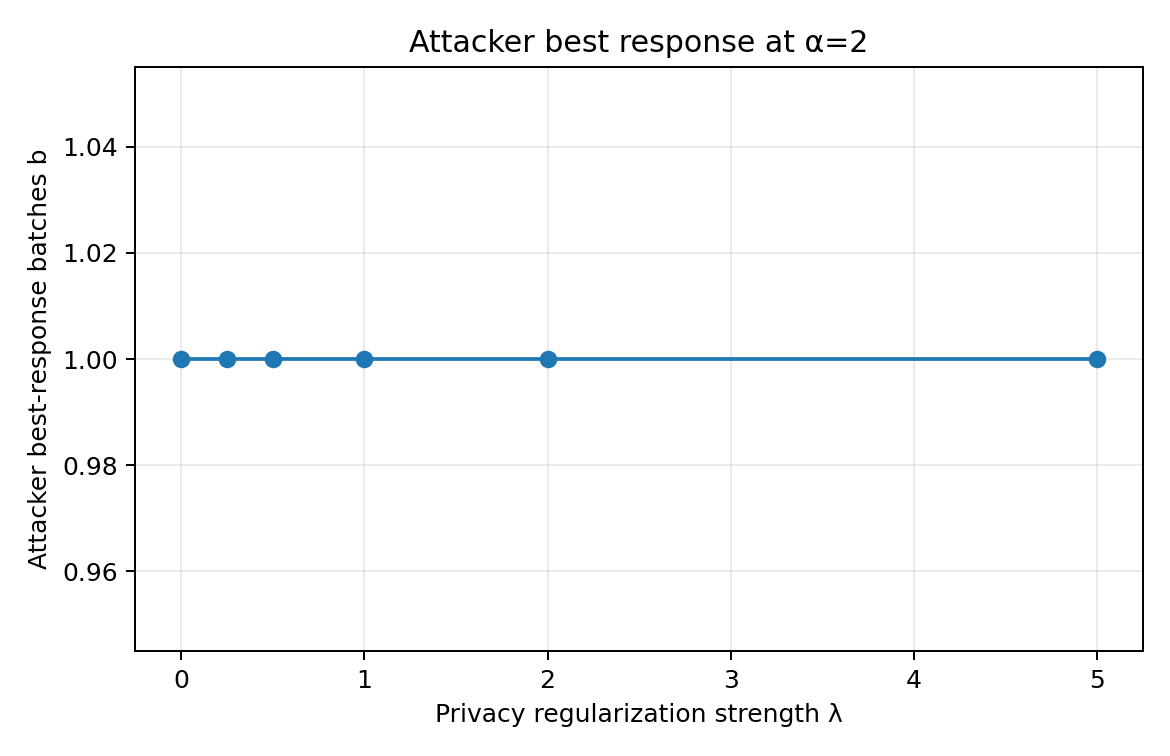

attacker_payoff_budget.png


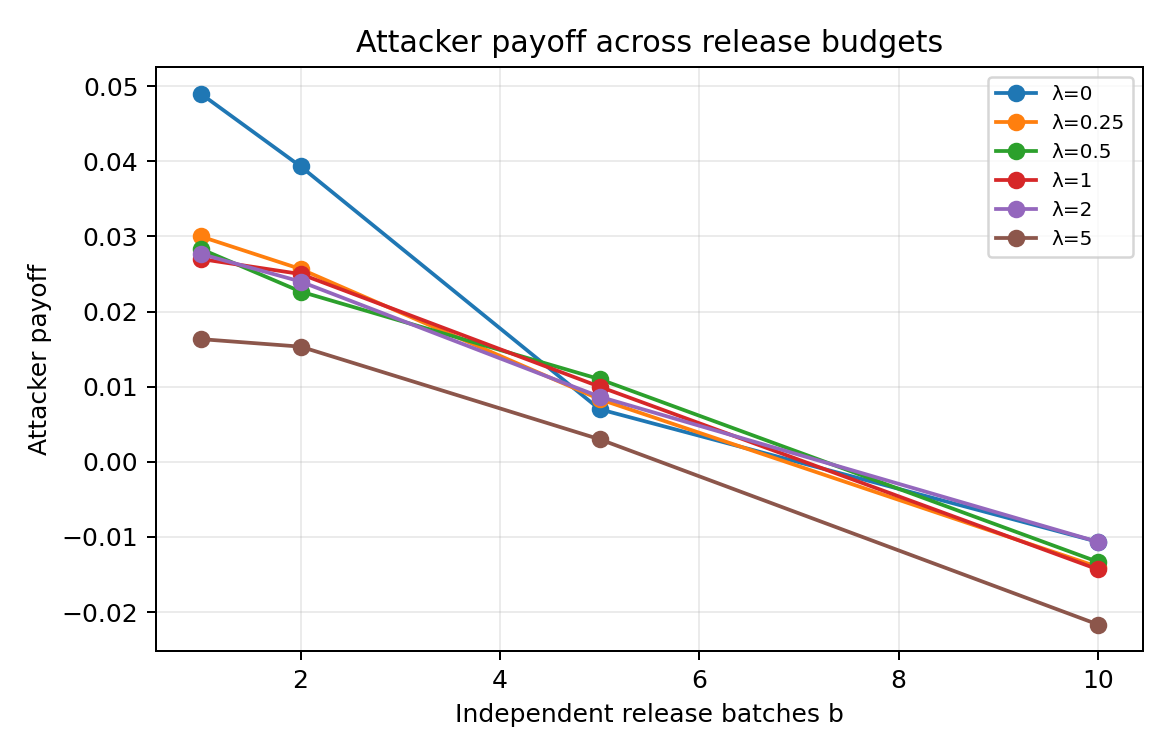

baseline_comparison.png


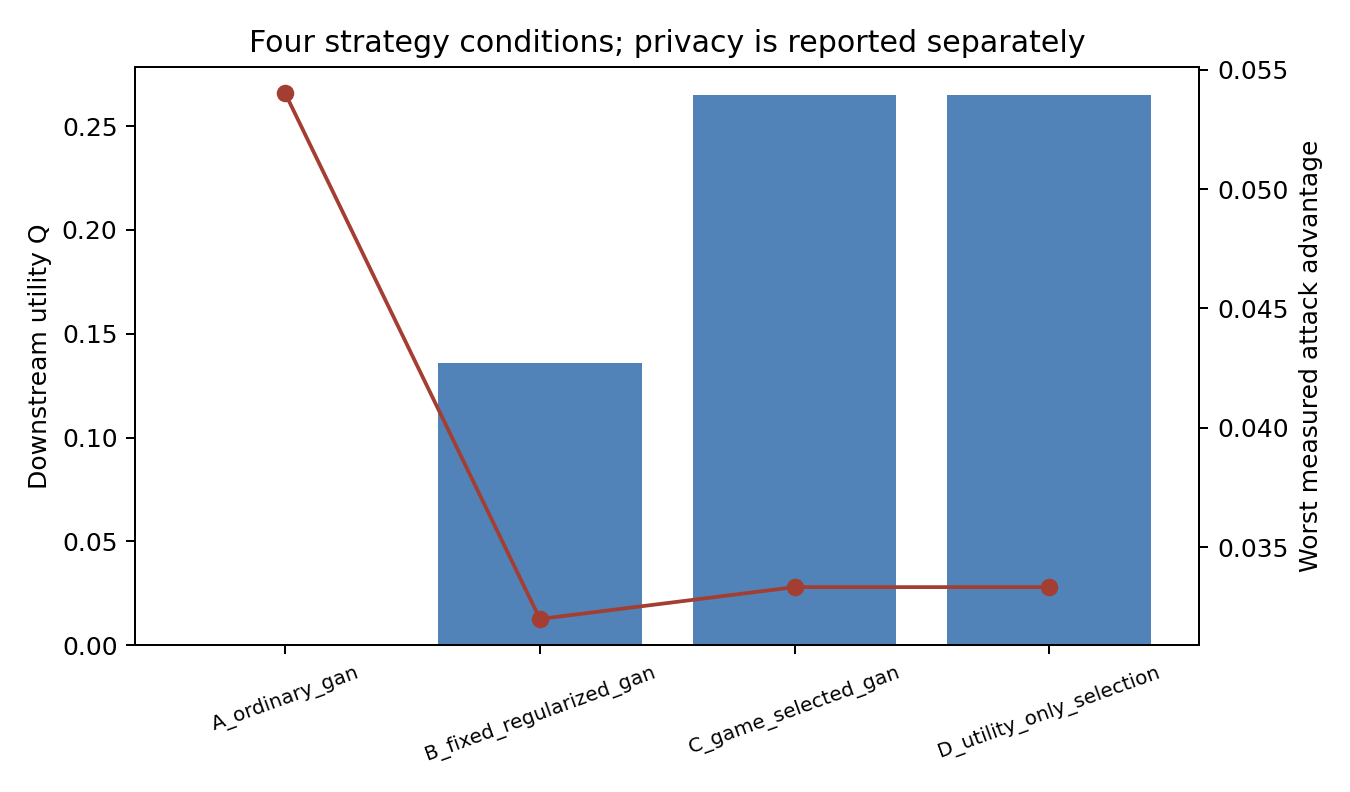

mia_advantage_vs_lambda.png


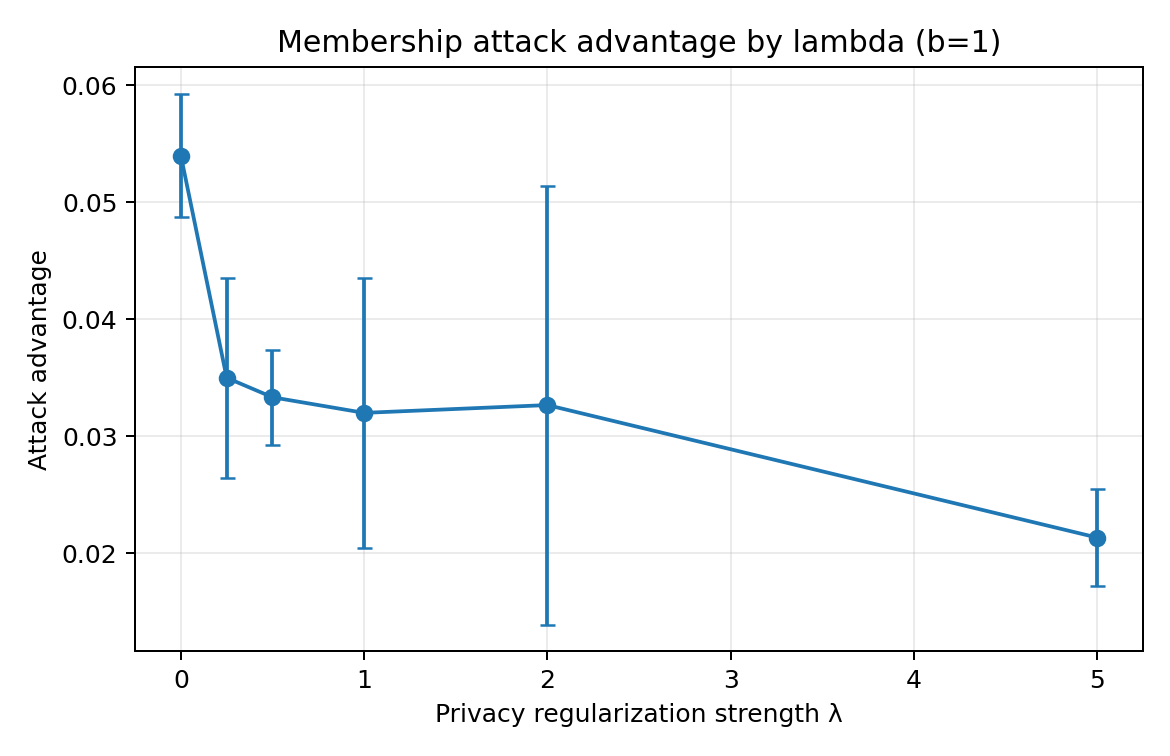

mia_auc_vs_lambda.png


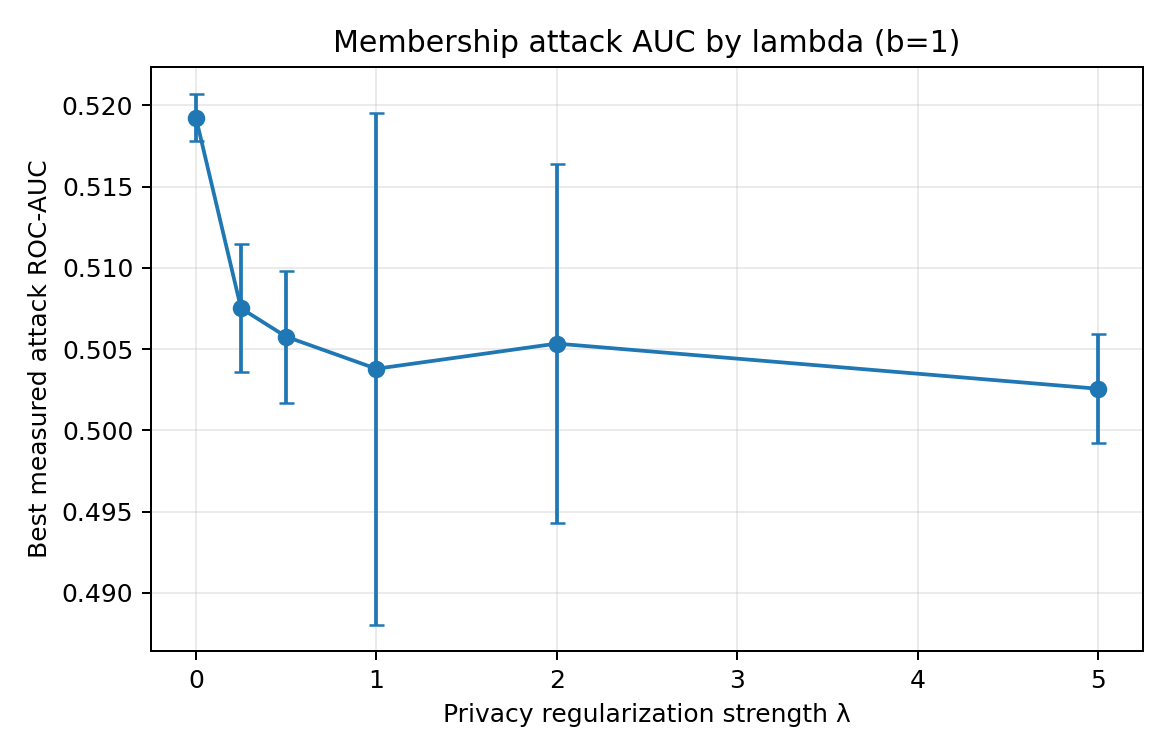

owner_alpha.png


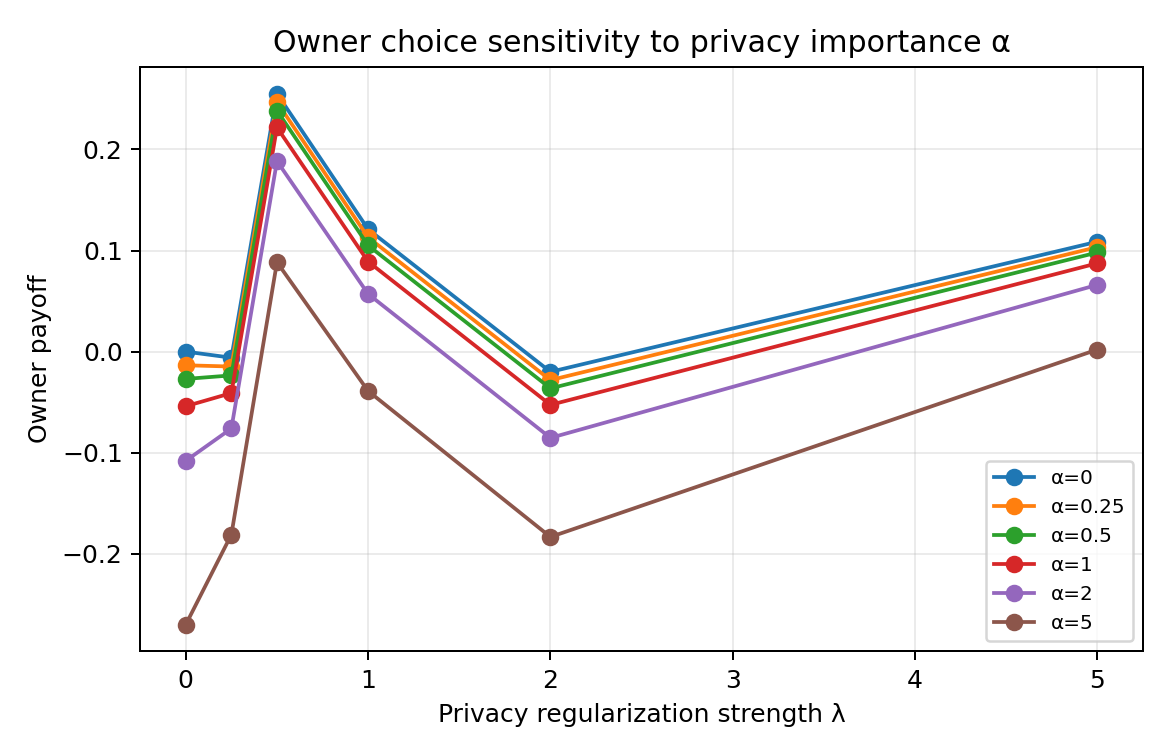

pareto.png


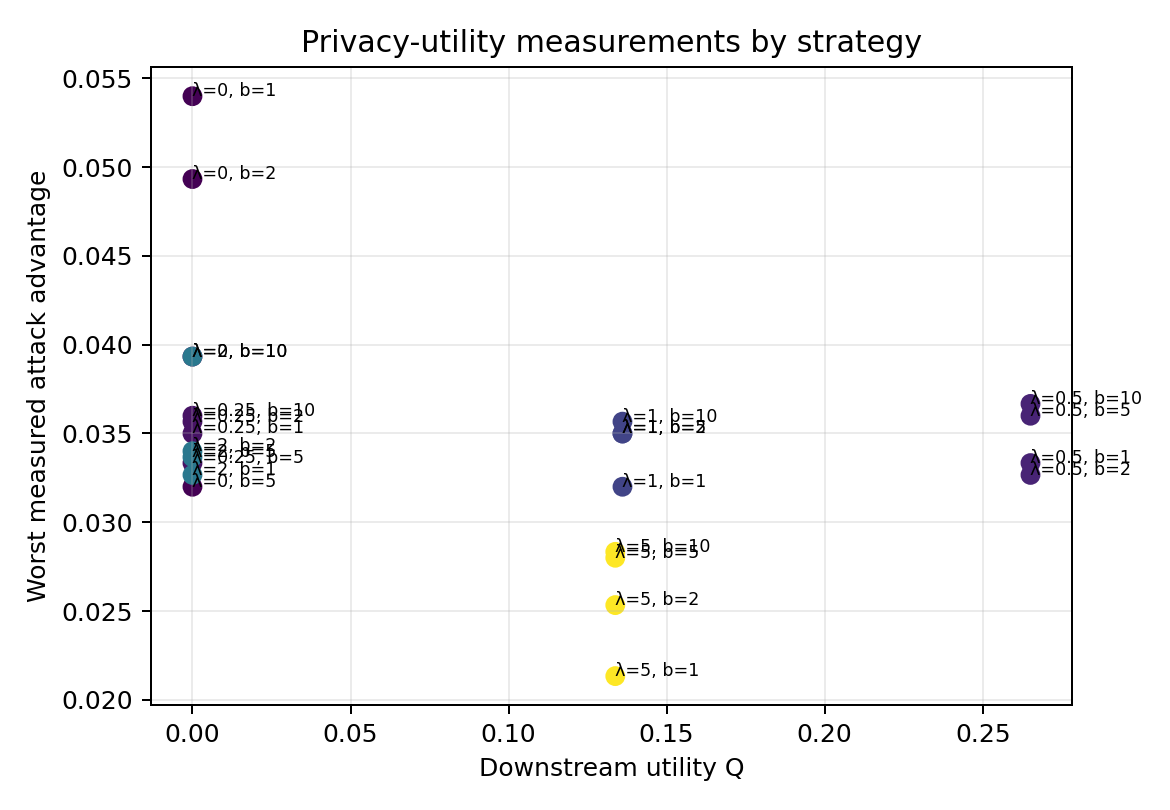

privacy_utility.png


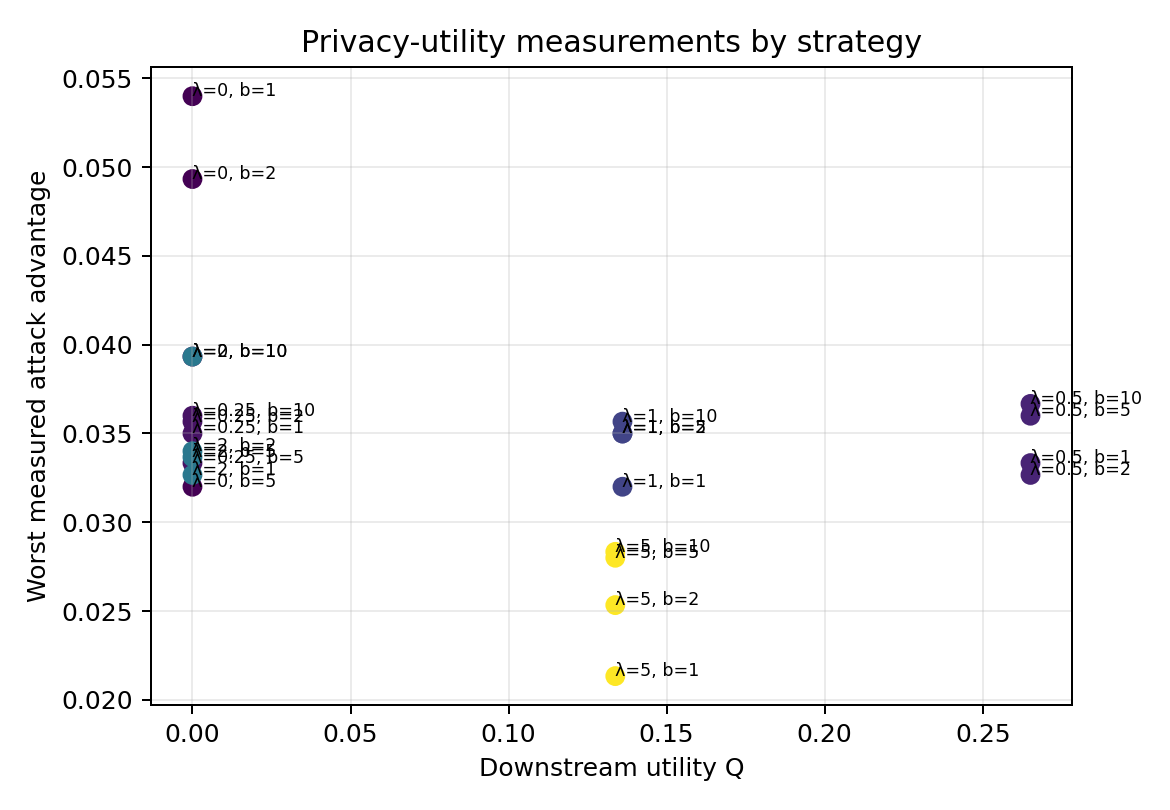

runtime_vs_lambda.png


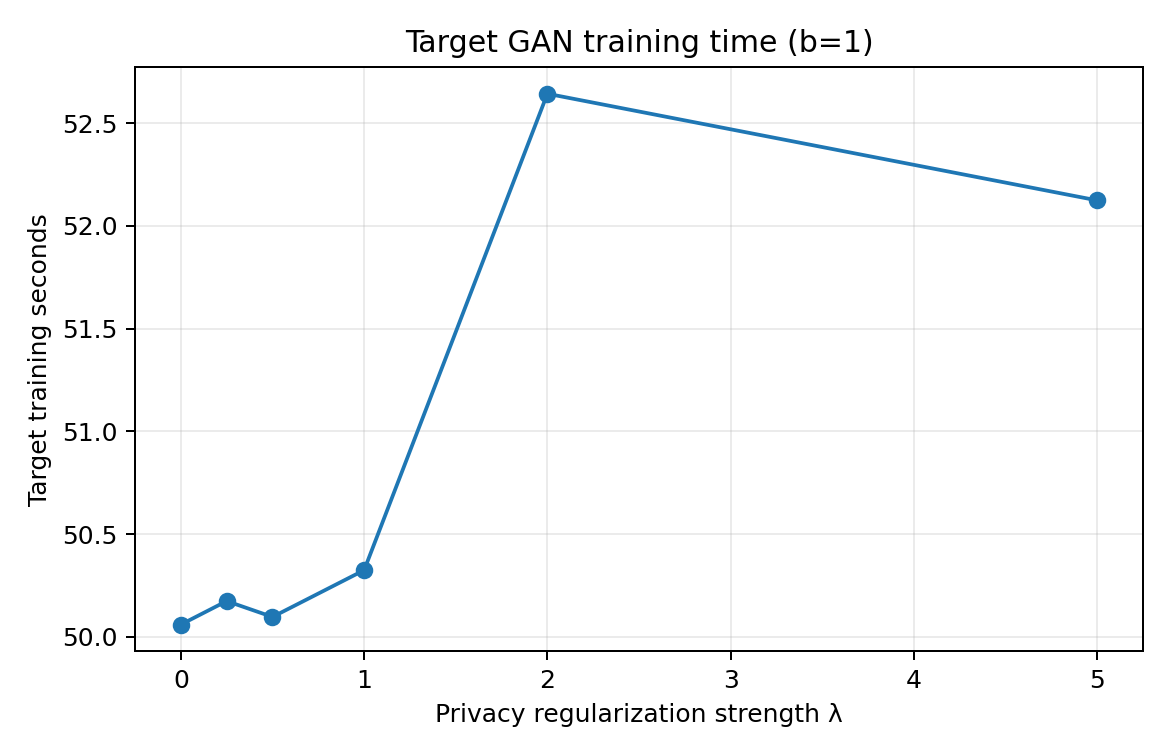

strategy_conditions.png


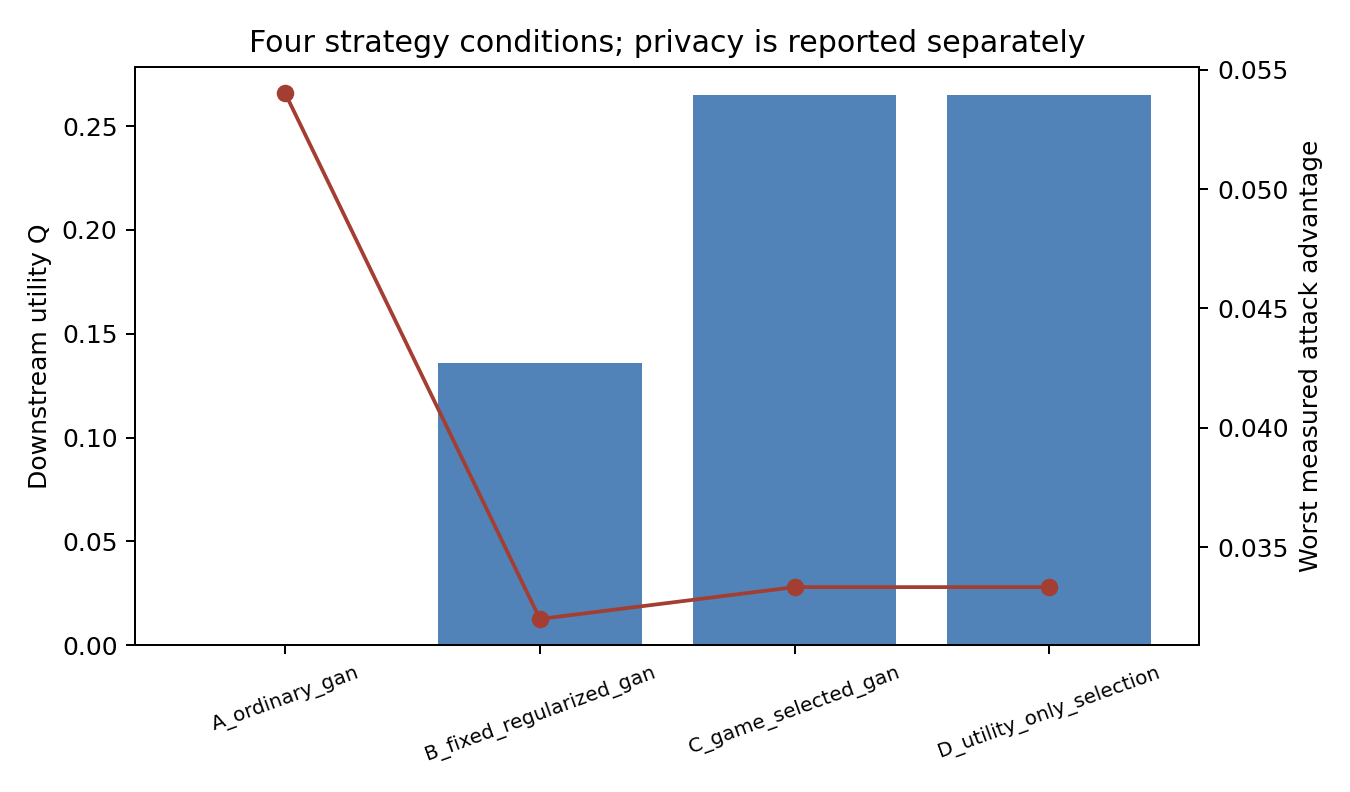

utility_vs_lambda.png


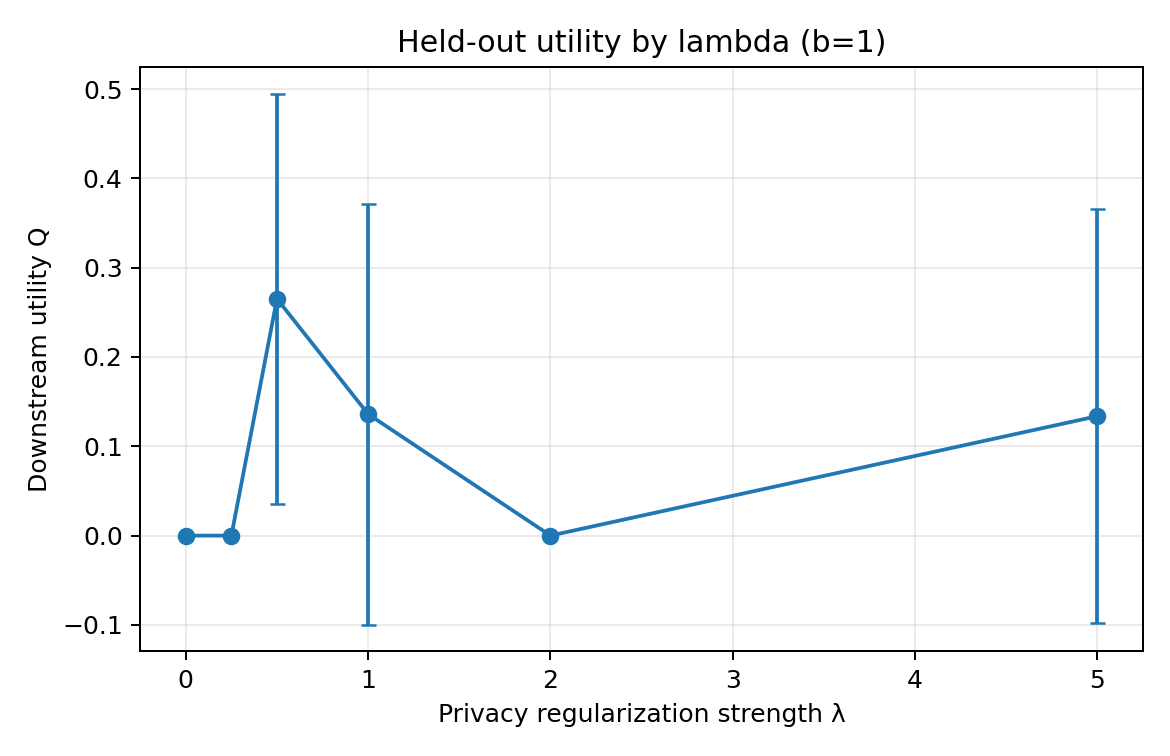

In [8]:
from IPython.display import Image, display as show
figure_dir = PROJECT_ROOT / config["paths"]["figures"]
for figure_path in sorted(figure_dir.glob("*.png")):
    print(figure_path.name)
    show(Image(filename=str(figure_path)))

## Outputs and notes

- Raw run results: `results/raw/`
- Aggregate tables: `results/tables/`
- Figures: `results/figures/`
- Research report: `reports/research_report.md`

The project’s privacy regularizer is an empirical heuristic and does not provide differential privacy. The smoke mode is for pipeline validation, not confirmatory research evidence.